In [2]:
# 作业4：Explore a data set
# 选取了美国国家环境信息中心(NCEI)网站上的Global Marine数据集，并下载了2008-06-01 00：00：00至2008-06-30 23:56:00的逐小时分钟数据
# 每行记录都包含海平面气压、海表温度、气温、风速在内的82种不同的海洋气象观测数据
# 因为经过4.1分析，发现上述4个主要变量种海平面气压数据最为丰富，缺测记录最少，因此选择该数据集中的海平面气压进行时间序列分析和统计分析
# 数据下载网址：https://www.ncei.noaa.gov/access/search/datasets/global-marine/
# 下载的数据文件名字为“40—50-130—120”，代表观测经纬度范围
# 该数据的详细介绍见报告

# 题目4.1 读取数据，清理缺失值和质量不合格的记录

# 质量筛选依据是：NCDC_QC_FLAGS第1位为报告位置标记，第6位为气压标记，1表示Correct
# 这次分析只保留这两个标记均为1的记录，并核对数据文档允许的气压范围

# 声明引入需要用到的库
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 先按字符串读取，保留站点编号和质量标记的原始形式，空字段和文字null都识别为缺失值
raw = pd.read_csv(
    "Global_Marine_20080601_20080630.csv",
    dtype="string",
    keep_default_na=False,
    na_values=["", " ", "null", "NULL"]
)
# 去除列名两端可能存在的空格，防止后续引用列变量名字时报错
raw.columns = raw.columns.str.strip()
# 输出相关信息测试
print("原始数据形状：", raw.shape)
print("站点或平台标识数量：", raw["STATION"].nunique())

# 第一步：比较主要变量的缺失比例
# 该数据的主要变量有海平面气压、海表温度、气温、风速，看一下哪个变量的缺失值最少，后续就选择哪个变量进行时间序列分析和统计分析
candidates = [
    "SEA_LVL_PRES", "SEA_SURF_TEMP",
    "AIR_TEMP", "WIND_SPEED"
]
# 使用apply()对这些列逐列执行数值转换，无法转换成数值的内容，也视为缺失
candidate_values = raw[candidates].apply(
    pd.to_numeric, errors="coerce"
)
missing_report = pd.DataFrame({
    "valid_count": candidate_values.notna().sum(),
    "missing_percent": candidate_values.isna().mean() * 100
}).sort_values("missing_percent")
# 输出4个主要变量的缺测情况，海平面气压的数据最丰富，缺测记录最少，故选择
print("\n主要变量的缺失情况：")
print(missing_report.round(2).to_string())

# 第二步：删除完全重复的行，要注意不同站点在同一时刻的观测不属于重复记录
audit = {"raw": len(raw)}
raw_unique = raw.drop_duplicates().copy()
audit["after_exact_duplicates"] = len(raw_unique)

# 第三步：提取气压分析需要的字段
columns = [
    "STATION", "DATE", "LATITUDE", "LONGITUDE",
    "SEA_LVL_PRES", "NCDC_QC_FLAGS"
]
data = raw_unique[columns].copy()
# 日期无法解析时记为NaT，保持数据下载时原始的UTC时间，不转换为北京时间
data["DATE"] = pd.to_datetime(data["DATE"], errors="coerce")
for column in ["LATITUDE", "LONGITUDE", "SEA_LVL_PRES"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")
# 根据文档原始气压单位为0.1hPa，因此需要除以10进行数值转换，如10226 → 1022.6hPa
data["SLP_hPa"] = data["SEA_LVL_PRES"] / 10

# 第四步：删除必要字段缺失的记录（如果该记录没有站点、日期、经纬、海平面气压这几个字段则直接删除）
# 文件中的其他变量：比如湿球温度、云量的缺失，不影响气压分析
data = data.dropna(subset=[
    "STATION", "DATE", "LATITUDE", "LONGITUDE", "SLP_hPa"
]).copy()
audit["after_required_missing"] = len(data)

# 第五步：检查时间和空间范围
# 左闭右开的区间包含6月30日的全部时刻
in_month = (
    (data["DATE"] >= "2008-06-01") &
    (data["DATE"] < "2008-07-01")
)
data = data.loc[in_month].copy()
audit["after_month_check"] = len(data)
# 文件对应40—50°N、130—120°W的区域
in_box = (
    data["LATITUDE"].between(40, 50) &
    data["LONGITUDE"].between(-130, -120)
)
data = data.loc[in_box].copy()
audit["after_coordinate_check"] = len(data)

# 第六步：检查气压字段允许的数值范围，根据IMMA文档给出的范围，排除明显错误的数据
data = data.loc[
    data["SLP_hPa"].between(870.0, 1074.6)
].copy()
audit["after_pressure_range"] = len(data)

# 第七步：根据气压相关质量标记筛选
data["record_qc"] = data["NCDC_QC_FLAGS"].str[0]
data["pressure_qc"] = data["NCDC_QC_FLAGS"].str[5]
good_qc = (
    (data["record_qc"] == "1") &
    (data["pressure_qc"] == "1")
)
# 做好质量控制，在数据缺少质量标记时，不视为通过
data = data.loc[good_qc.fillna(False)].copy()
audit["after_ncdc_qc"] = len(data)
# 输出质量控制的相关信息
print("\n清洗过程中各步骤保留的记录数：")
print(pd.Series(audit, name="remaining_rows").to_string())

原始数据形状： (53985, 88)
站点或平台标识数量： 192

主要变量的缺失情况：
               valid_count  missing_percent
SEA_LVL_PRES         36229            32.89
SEA_SURF_TEMP        35073            35.03
AIR_TEMP             33703            37.57
WIND_SPEED           27027            49.94

清洗过程中各步骤保留的记录数：
raw                       53985
after_exact_duplicates    53985
after_required_missing    36229
after_month_check         36229
after_coordinate_check    36229
after_pressure_range      36229
after_ncdc_qc             36224



站点有效记录数： 720
站点坐标：
 LATITUDE  LONGITUDE
     47.7     -124.5
每小时记录数的最小值、最大值： 1 1
逐小时序列长度： 720
缺测小时数： 0
小时完整率(%)： 100.0


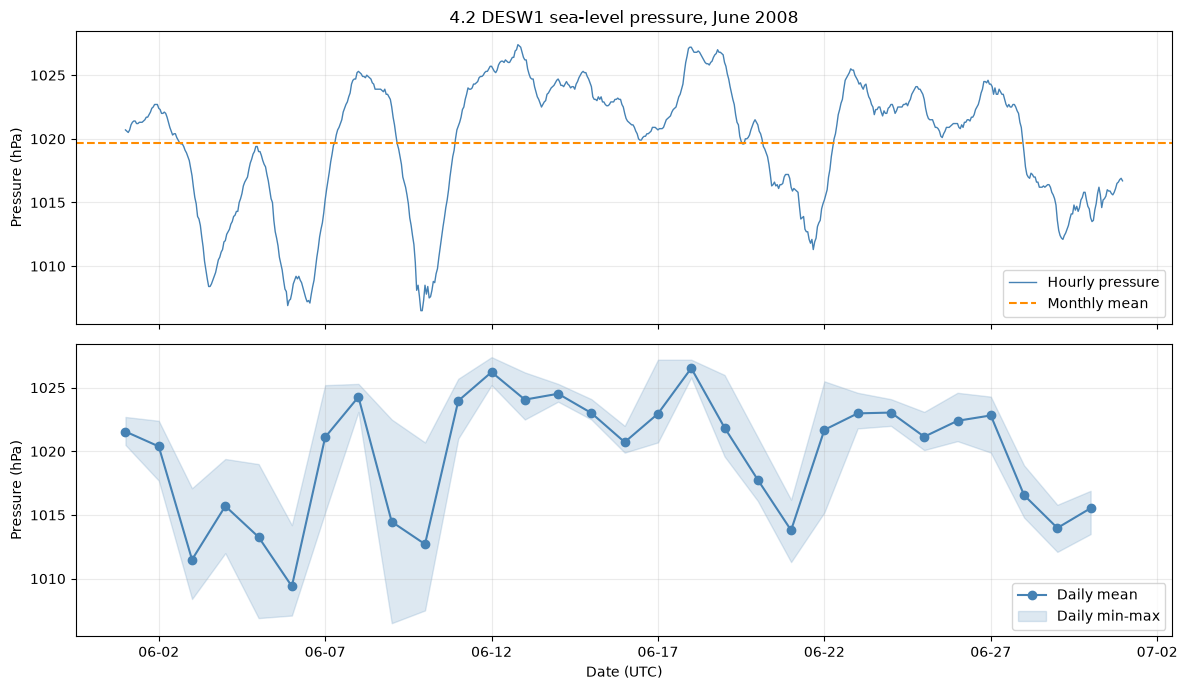

In [3]:
# 题目4.2：绘制海平面气压时间序列

# 第一步：选取一个固定站点的数据进行处理，这里选取DESW1站点
# 因为这个文件装的是区域内不同平台的逐次观测，并非整个10°区域的平均时间序列。因此分析固定一个站点，避免把不同地点的差异混入时间变化
station_id = "DESW1"
station = (
    data.loc[data["STATION"] == station_id]
        .sort_values("DATE")
        .copy()
)
# 输出该站点的相关数据信息
print("\n站点有效记录数：", len(station))
print("站点坐标：")
print(
    station[["LATITUDE", "LONGITUDE"]]
    .drop_duplicates()
    .to_string(index=False)
)
station = station.set_index("DATE")

# 第二步：建立完整的逐小时时间轴
all_hours = pd.date_range(
    "2008-06-01 00:00",
    "2008-06-30 23:00",
    freq="h"
)
# 核对每小时有多少条记录。
hourly_count = (
    station.resample("h")
           .size()
           .reindex(all_hours, fill_value=0)
)
# 输出每小时的记录数范围
print(
    "每小时记录数的最小值、最大值：",
    hourly_count.min(), hourly_count.max()
)
# 按小时取平均，得到规范的逐小时序列，该站每小时恰好一条记录，因此不会改变原始气压值。
hourly = (
    station["SLP_hPa"]
    .resample("h")
    .mean()
    .reindex(all_hours)
    .astype(float)
)
# 缺测保持 NaN，不用 0 填充，也不插值
hourly.index.name = "DATE_UTC"
hourly.name = "SLP_hPa"
# 输出时间序列信息处理情况，为画图做准备
print("逐小时序列长度：", len(hourly))
print("缺测小时数：", hourly.isna().sum())
print("小时完整率(%)：", round(hourly.notna().mean() * 100, 2))
# 使用resample("D")按天进行重采样，每天计算有效小时数、平均值、最小值、最大值和标准差
daily = hourly.resample("D").agg(
    ["count", "mean", "min", "max", "std"]
)
# 第三步：开始绘图，创建画布和子图变量（上下两张图）
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)
# 设置上图“逐小时气压”的参数
axes[0].plot(
    hourly.index,
    hourly.to_numpy(),
    color="steelblue",
    linewidth=1,
    label="Hourly pressure"
)
# 用虚线表示全月平均值
axes[0].axhline(
    hourly.mean(),
    color="darkorange",
    linestyle="--",
    label="Monthly mean"
)
axes[0].set(
    title="4.2 DESW1 sea-level pressure, June 2008",
    ylabel="Pressure (hPa)"
)
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.25)

# 设置下图“日均气压和当日变化范围”的参数
axes[1].plot(
    daily.index,
    daily["mean"],
    "o-",
    color="steelblue",
    label="Daily mean"
)
# 阴影表示当日最小值至最大值
axes[1].fill_between(
    daily.index,
    daily["min"],
    daily["max"],
    color="steelblue",
    alpha=0.18,
    label="Daily min-max"
)
axes[1].set(
    xlabel="Date (UTC)",
    ylabel="Pressure (hPa)"
)
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.25)
# 日期标签以“月-日”显示，每隔大概5天一个标签
axes[1].xaxis.set_major_locator(
    mdates.DayLocator(interval=5)
)
axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%m-%d")
)

fig.tight_layout()
plt.show()

In [4]:
# 题目4.3：至少进行5项简单统计检查，并报告发现（DESW1单站在2008年6月的气压情况）
# 以下是各项统计检查的结果，对各项统计数据的分析发现请见报告

# 1、统计集中趋势：平均值和中位数
print("1. 集中趋势")
print("平均值：", round(hourly.mean(), 3))
print("中位数：", round(hourly.median(), 3))

# 2、统计离散程度：标准差和极差
# 使用std()默认计算样本标准差，即ddof=1
print("\n2. 离散程度")
print("标准差：", round(hourly.std(), 3))
print("极差：", round(hourly.max() - hourly.min(), 3))

# 3、统计四分位数、IQR 和潜在异常值
# Q1：第25百分位数；Q3：第75百分位数
q1 = hourly.quantile(0.25)
q3 = hourly.quantile(0.75)
iqr = q3 - q1
# 常见的 1.5 IQR 检查界限。
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = hourly[(hourly < lower) | (hourly > upper)]
print("\n3. 四分位数与IQR检查")
print("Q1、Q3、IQR：",
      round(q1, 3), round(q3, 3), round(iqr, 3))
print("检查下限、上限：",
      round(lower, 3), round(upper, 3))
print("超出界限的记录数：", len(outliers))

# 4、统计气压极值及其发生时间
# 使用idxmin()、idxmax()返回极值所在的时间，如果存在并列极值，返回第一次出现的时间
print("\n4. 逐小时极值，时间为 UTC")
print("最低气压：", hourly.min(),
      "时间：", hourly.idxmin())
print("最高气压：", hourly.max(),
      "时间：", hourly.idxmax())

# 5、统计海平面的日尺度变化
daily_range = daily["max"] - daily["min"]
print("\n5. 日尺度特征")
print("最低日均气压：",
      round(daily["mean"].min(), 3),
      "日期：", daily["mean"].idxmin().date())
print("最高日均气压：",
      round(daily["mean"].max(), 3),
      "日期：", daily["mean"].idxmax().date())
print("最大日内气压范围：",
      round(daily_range.max(), 3),
      "日期：", daily_range.idxmax().date())
print("每天有效小时数的范围：",
      daily["count"].min(), daily["count"].max())

# 6、统计相邻小时和相邻日海平面气压的变化
# 时间轴已经补齐，因此diff()对应相邻小时之差，原始精度是 0.1 hPa，小时差也保留一位小数。
hourly_change = hourly.diff().round(1)
daily_change = daily["mean"].diff()
print("\n7. 相邻时刻变化")
print("最大小时下降：", hourly_change.min(),
      "时段结束时间：", hourly_change.idxmin())
print("最大小时上升：", hourly_change.max(),
      "时段结束时间：", hourly_change.idxmax())
print("日均值最大下降：", round(daily_change.min(), 3),
      "日期：", daily_change.idxmin().date())
print("日均值最大上升：", round(daily_change.max(), 3),
      "日期：", daily_change.idxmax().date())

1. 集中趋势
平均值： 1019.665
中位数： 1021.2

2. 离散程度
标准差： 5.101
极差： 20.9

3. 四分位数与IQR检查
Q1、Q3、IQR： 1016.1 1023.6 7.5
检查下限、上限： 1004.85 1034.85
超出界限的记录数： 0

4. 逐小时极值，时间为 UTC
最低气压： 1006.5 时间： 2008-06-09 21:00:00
最高气压： 1027.4 时间： 2008-06-12 19:00:00

5. 日尺度特征
最低日均气压： 1009.396 日期： 2008-06-06
最高日均气压： 1026.533 日期： 2008-06-18
最大日内气压范围： 16.0 日期： 2008-06-09
每天有效小时数的范围： 24 24

7. 相邻时刻变化
最大小时下降： -2.2 时段结束时间： 2008-06-09 18:00:00
最大小时上升： 1.2 时段结束时间： 2008-06-10 00:00:00
日均值最大下降： -9.808 日期： 2008-06-09
日均值最大上升： 11.712 日期： 2008-06-07
